# 📊 Tugas 2: ETL Pipeline Data Sensor IoT dengan Python Pandas
**Mata Kuliah:** Pemrograman Integrasi Data (PID)  
**Mahasiswa:** Hayqal Husein Alhabsyi  
**NIM:** 245150301111027  
**Repository Asal:** [abazh/PID – ETL-Pandas](https://github.com/abazh/PID/tree/main/ETL-Pandas)  

---
### 🎯 Capaian Pembelajaran & Cakupan Penugasan:
1. **Extract (15%)**: Ekstraksi multi-format (`sensor_data_main.csv`, `sensor_data_semicolon.csv`, `sensor_data_monthly.xlsx` seluruh sheet dinamis, dan `sensor_config.json`) dengan error handling dan penggabungan skema konsisten. Profil awal data (dimensi, tipe data, missing value, duplikat).
2. **Transform – Data Cleaning (20%)**: Penghapusan duplikat, standarisasi nama kolom (*snake_case*), konversi tipe data eksplisit (datetime, numerik, kategori), normalisasi kategorikal, dan deteksi outlier komparatif (*IQR vs Z-Score*) disertai justifikasi keputusan *capping*.
3. **Transform – Missing Values (15%)**: Pengujian dan perbandingan minimal dua strategi (Time-Series Forward Fill/Interpolasi Linear vs Group-Based Median), tabel perbandingan statistik deskriptif sebelum vs sesudah, dan justifikasi pemilihan strategi *hybrid*.
4. **Transform – Feature Engineering (20%)**: Fitur waktu (*hour, day, week, day of week, weekend*), kategorisasi periode waktu (*pagi/siang/sore/malam* via vektorisasi `pd.cut`), konversi suhu (°F, K), kategorisasi AQI standar EPA/ISPU, Indeks Kenyamanan Termal (*Thom's Discomfort Index*), *Rolling statistics* (Moving Average 24 jam per sensor), dan Fitur Orisinal: **TESI** (*Thermal Environmental Stress Index*).
5. **Validasi & Load (15%)**: Validasi rentang sensor dan skor kualitas data 4 dimensi (*Completeness, Validity, Uniqueness, Consistency*) Sebelum vs Sesudah ETL; Ekspor 4 format (CSV, Excel Multi-Sheet data bersih lengkap + ringkasan, JSON, Parquet) dan tabel perbandingan ukuran file.
6. **Analisis & Dokumentasi (15%)**: Minimal 3 visualisasi utama beserta interpretasinya (Tren waktu multi-lokasi, Heatmap matriks korelasi, Distribusi parameter sebelum vs sesudah pembersihan, dan Siklus diurnal 24 jam) serta Kesimpulan komprehensif.


## 1. Setup Lingkungan & Import Required Libraries
Mengimpor seluruh pustaka yang diperlukan untuk manipulasi data, analisis deret waktu, kalkulasi kualitas data, dan visualisasi.


In [1]:
# Import libraries untuk data manipulation dan analysis
import os
import json
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Set visual & display options
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except Exception:
    plt.style.use('default')

sns.set_palette("husl")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 25)
pd.set_option('display.float_format', '{:.2f}'.format)
pd.set_option('display.width', 1000)

def calculate_data_quality_comprehensive(df):
    """
    Menghitung skor kualitas data komprehensif mencakup 4 dimensi:
    1. Completeness (% cell yang tidak missing)
    2. Validity     (% nilai data dalam range fisik operasional yang valid)
    3. Uniqueness   (% baris yang tidak duplikat)
    4. Consistency  (% data yang konsisten format casing dan tipe datanya)
    """
    quality_scores = {}
    if df is None or df.empty:
        return {'completeness': 0.0, 'validity': 0.0, 'uniqueness': 0.0, 'consistency': 0.0, 'overall': 0.0}

    # 1. Completeness
    total_cells = df.size
    missing_cells = df.isnull().sum().sum()
    quality_scores['completeness'] = float(((total_cells - missing_cells) / total_cells) * 100) if total_cells > 0 else 100.0

    # 2. Validity
    valid_ranges = {
        'temperature_celsius': (-10.0, 50.0),
        'humidity_percent': (0.0, 100.0),
        'pressure_hpa': (950.0, 1050.0),
        'air_quality_aqi': (0.0, 500.0)
    }
    validity_scores = []
    for col, (min_val, max_val) in valid_ranges.items():
        if col in df.columns:
            non_null = pd.to_numeric(df[col], errors='coerce').dropna()
            if len(non_null) > 0:
                valid_count = ((non_null >= min_val) & (non_null <= max_val)).sum()
                validity_scores.append((valid_count / len(non_null)) * 100)
    quality_scores['validity'] = float(np.mean(validity_scores)) if validity_scores else 100.0

    # 3. Uniqueness
    total_rows = len(df)
    if total_rows > 0:
        unique_rows = len(df.drop_duplicates())
        quality_scores['uniqueness'] = float((unique_rows / total_rows) * 100)
    else:
        quality_scores['uniqueness'] = 100.0

    # 4. Consistency
    consistency_scores = []
    if 'location' in df.columns:
        loc_s = df['location'].dropna().astype(str)
        is_title = loc_s.apply(lambda s: s.istitle() or s.startswith('Location_'))
        consistency_scores.append((is_title.sum() / len(loc_s)) * 100)
    if 'status' in df.columns:
        stat_s = df['status'].dropna().astype(str)
        valid_stat = stat_s.isin(['active', 'maintenance'])
        consistency_scores.append((valid_stat.sum() / len(stat_s)) * 100)
    if 'timestamp' in df.columns:
        is_dt = pd.api.types.is_datetime64_any_dtype(df['timestamp'])
        consistency_scores.append(100.0 if is_dt else 70.0)
    quality_scores['consistency'] = float(np.mean(consistency_scores)) if consistency_scores else 100.0

    # Overall Weighted Score
    weights = {'completeness': 0.30, 'validity': 0.30, 'uniqueness': 0.20, 'consistency': 0.20}
    quality_scores['overall'] = float(sum(quality_scores[k] * weights[k] for k in weights.keys()))
    return quality_scores

print("✅ Environment setup berhasil!")
print(f"📦 Pandas version : {pd.__version__}")
print(f"📦 NumPy version  : {np.__version__}")
print("🎯 Fungsi evaluasi kualitas data (4 Dimensi) siap digunakan.")


✅ Environment setup berhasil!
📦 Pandas version : 3.0.6
📦 NumPy version  : 2.4.6
🎯 Fungsi evaluasi kualitas data (4 Dimensi) siap digunakan.


## 2. Persiapan Data Mentah (Generate Sample Data)
Memastikan seluruh berkas data simulasi mentah tersedia pada folder `data/raw/` sebelum proses ETL dimulai.


In [2]:
# Verifikasi ketersediaan berkas raw data
import subprocess

expected_files = [
    'data/raw/sensor_data_main.csv',
    'data/raw/sensor_data_semicolon.csv',
    'data/raw/sensor_data_monthly.xlsx',
    'data/raw/sensor_config.json'
]

missing_raw = [f for f in expected_files if not os.path.exists(f)]
if missing_raw:
    print(f"⚠️ Berkas belum lengkap: {missing_raw}. Menjalankan generator simulasi...")
    script_path = os.path.join('scripts', 'generate_sample_data.py')
    res = subprocess.run([sys.executable, script_path], capture_output=True, text=True)
    print(res.stdout)
    print("✅ Berkas data simulasi berhasil di-generate!")
else:
    print("✅ Seluruh 4 berkas raw data telah tersedia di data/raw/:")
    for f in expected_files:
        print(f"   - {f} ({os.path.getsize(f) / 1024:.2f} KB)")


✅ Seluruh 4 berkas raw data telah tersedia di data/raw/:
   - data/raw/sensor_data_main.csv (1025.77 KB)
   - data/raw/sensor_data_semicolon.csv (70.99 KB)
   - data/raw/sensor_data_monthly.xlsx (609.94 KB)
   - data/raw/sensor_config.json (4.52 KB)


## 3. Tahap EXTRACT (Bobot 15%)
Mengekstrak data dari berbagai format file:
1. `sensor_data_main.csv` (CSV standar pembatas koma).
2. `sensor_data_semicolon.csv` (CSV pembatas titik-koma `;`).
3. `sensor_data_monthly.xlsx` (Excel multi-sheet, dibaca secara dinamis untuk seluruh sheet).
4. `sensor_config.json` (Konfigurasi dan metadata sensor).

Semua data digabungkan ke dalam satu DataFrame tunggal dengan skema yang konsisten, disertai implementasi *error handling* (`try-except`).


In [3]:
# 3.1 Ekstraksi Multi-Format dengan Error Handling
print("🔄 EXTRACT: Membaca Data dari Berbagai Sumber Format...")
print("=" * 70)

# 1. Baca CSV Utama
try:
    csv_main_path = 'data/raw/sensor_data_main.csv'
    df_main_raw = pd.read_csv(csv_main_path)
    print(f"✅ [CSV Main]        : Berhasil memuat {df_main_raw.shape[0]:,} baris, {df_main_raw.shape[1]} kolom")
except Exception as e:
    print(f"❌ [CSV Main] Gagal  : {e}")
    df_main_raw = pd.DataFrame()

# 2. Baca CSV Semicolon
try:
    csv_semi_path = 'data/raw/sensor_data_semicolon.csv'
    df_semicolon_raw = pd.read_csv(csv_semi_path, sep=';')
    print(f"✅ [CSV Semicolon]   : Berhasil memuat {df_semicolon_raw.shape[0]:,} baris, {df_semicolon_raw.shape[1]} kolom")
except Exception as e:
    print(f"❌ [CSV Semicolon]   : {e}")
    df_semicolon_raw = pd.DataFrame()

# 3. Baca Excel Multi-Sheet Secara Dinamis (Seluruh Sheet)
monthly_dfs = []
try:
    excel_path = 'data/raw/sensor_data_monthly.xlsx'
    excel_sheets_dict = pd.read_excel(excel_path, sheet_name=None)
    print(f"✅ [Excel Multi-Sheet]: Ditemukan {len(excel_sheets_dict)} sheet: {list(excel_sheets_dict.keys())}")
    for sheet_name, sheet_df in excel_sheets_dict.items():
        print(f"   - Sheet '{sheet_name}': {sheet_df.shape[0]:,} baris, {sheet_df.shape[1]} kolom")
        monthly_dfs.append(sheet_df)
    df_excel_combined = pd.concat(monthly_dfs, ignore_index=True) if monthly_dfs else pd.DataFrame()
except Exception as e:
    print(f"❌ [Excel Multi-Sheet]: {e}")
    df_excel_combined = pd.DataFrame()

# 4. Baca JSON Sensor Configuration
df_config = pd.DataFrame()
try:
    json_path = 'data/raw/sensor_config.json'
    with open(json_path, 'r', encoding='utf-8') as f:
        sensor_config = json.load(f)
    df_config = pd.DataFrame(sensor_config)
    print(f"✅ [JSON Config]     : Berhasil memuat {len(df_config)} metadata konfigurasi sensor")
    print(f"   Kolom metadata     : {list(df_config.columns)}")
except Exception as e:
    print(f"❌ [JSON Config]     : {e}")

# 5. Gabungkan Menjadi Satu DataFrame Konsisten
print("-" * 70)
readings_dfs = [df for df in [df_main_raw, df_semicolon_raw, df_excel_combined] if not df.empty]
if not readings_dfs:
    raise RuntimeError("Gagal mengekstrak data: Tidak ada sumber dataset yang dapat dibaca.")

# Gabungkan data pembacaan deret waktu sensor
df_readings_combined = pd.concat(readings_dfs, ignore_index=True)

# Integrasikan metadata sensor (installation_date & calibration_date) dari JSON konfigurasi
if not df_config.empty and 'sensor_id' in df_config.columns:
    meta_cols = [c for c in ['sensor_id', 'installation_date', 'calibration_date'] if c in df_config.columns]
    df_raw_combined = pd.merge(df_readings_combined, df_config[meta_cols], on='sensor_id', how='left')
    print(f"🔗 Metadata JSON (installation & calibration date) berhasil di-merge berdasarkan sensor_id.")
else:
    df_raw_combined = df_readings_combined.copy()

df_main = df_raw_combined.copy()
print(f"🎉 SUKSES! Seluruh sumber data berhasil diintegrasikan ke dalam satu DataFrame.")
print(f"   Total Baris Gabungan : {df_main.shape[0]:,} baris")
print(f"   Total Kolom          : {df_main.shape[1]} kolom")
print(f"   Daftar Kolom         : {list(df_main.columns)}")


🔄 EXTRACT: Membaca Data dari Berbagai Sumber Format...
✅ [CSV Main]        : Berhasil memuat 14,472 baris, 8 kolom
✅ [CSV Semicolon]   : Berhasil memuat 1,000 baris, 8 kolom


✅ [Excel Multi-Sheet]: Ditemukan 2 sheet: ['January', 'February']
   - Sheet 'January': 7,479 baris, 8 kolom
   - Sheet 'February': 6,993 baris, 8 kolom
✅ [JSON Config]     : Berhasil memuat 10 metadata konfigurasi sensor
   Kolom metadata     : ['sensor_id', 'location', 'installation_date', 'calibration_date', 'specifications']
----------------------------------------------------------------------
🔗 Metadata JSON (installation & calibration date) berhasil di-merge berdasarkan sensor_id.
🎉 SUKSES! Seluruh sumber data berhasil diintegrasikan ke dalam satu DataFrame.
   Total Baris Gabungan : 29,944 baris
   Total Kolom          : 10 kolom
   Daftar Kolom         : ['timestamp', 'sensor_id', 'location', 'temperature_celsius', 'humidity_percent', 'pressure_hpa', 'air_quality_aqi', 'status', 'installation_date', 'calibration_date']


## 4. Pemeriksaan Profil Awal Data (Initial Data Profiling & Baseline Score)
Menampilkan profil dataset gabungan mentah sebelum pembersihan data: dimensi, tipe data, jumlah nilai kosong (*missing*), dan baris duplikat, serta mengukur skor kualitas data awal.


In [4]:
# 4.1 Profil Awal Dataset Gabungan
print("📊 PROFIL AWAL DATASET GABUNGAN (INITIAL DATA PROFILING)")
print("=" * 70)
print(f"1. Dimensi Data (Baris, Kolom) : {df_main.shape[0]:,} baris x {df_main.shape[1]} kolom")
print(f"2. Penggunaan Memori Awal     : {df_main.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"3. Total Baris Duplikat Awal  : {df_main.duplicated().sum():,} baris ({df_main.duplicated().mean()*100:.2f}%)")
print(f"4. Total Sel Kosong (Missing) : {df_main.isnull().sum().sum():,} sel ({df_main.isnull().sum().sum() / df_main.size * 100:.2f}%)")
print()

print("📋 Tipe Data dan Missing Value per Kolom:")
print("-" * 70)
profiling_df = pd.DataFrame({
    'Kolom': df_main.columns,
    'Tipe Data': df_main.dtypes.astype(str),
    'Non-Null Count': df_main.count().values,
    'Missing Count': df_main.isnull().sum().values,
    'Missing (%)': (df_main.isnull().mean().values * 100).round(2),
    'Jumlah Unik': [df_main[c].nunique() for c in df_main.columns]
})
print(profiling_df.to_string(index=False))
print()

print("🔢 Statistik Deskriptif Numerik Awal:")
print("-" * 70)
print(df_main.describe().round(2))


📊 PROFIL AWAL DATASET GABUNGAN (INITIAL DATA PROFILING)
1. Dimensi Data (Baris, Kolom) : 29,944 baris x 10 kolom
2. Penggunaan Memori Awal     : 6.38 MB
3. Total Baris Duplikat Awal  : 1,120 baris (3.74%)
4. Total Sel Kosong (Missing) : 1,448 sel (0.48%)

📋 Tipe Data dan Missing Value per Kolom:
----------------------------------------------------------------------


              Kolom Tipe Data  Non-Null Count  Missing Count  Missing (%)  Jumlah Unik
          timestamp    object           29944              0         0.00         2880
          sensor_id       str           29944              0         0.00           10
           location       str           29944              0         0.00           10
temperature_celsius   float64           29367            577         1.93         2497
   humidity_percent   float64           29073            871         2.91          490
       pressure_hpa   float64           29944              0         0.00         4176
    air_quality_aqi   float64           29944              0         0.00         1058
             status       str           29944              0         0.00            2
  installation_date       str           29944              0         0.00            1
   calibration_date       str           29944              0         0.00            1

🔢 Statistik Deskriptif Numerik Awal:
-----

In [5]:
# 4.2 Evaluasi Skor Kualitas Data Awal (SEBELUM ETL)
print("🔍 EVALUASI SKOR KUALITAS DATA AWAL (SEBELUM ETL)")
print("=" * 65)
initial_scores = calculate_data_quality_comprehensive(df_main)
for metric, score in initial_scores.items():
    badge = '🌟' if score >= 90 else ('⚠️' if score >= 75 else '❌')
    print(f"{badge} {metric.title():22}: {score:6.2f}%")
print("-" * 65)
print("💡 Temuan Awal: Terdapat baris duplikat, inkonsistensi penamaan/casing lokasi,")
print("   missing values pada pengukuran sensor, dan nilai ekstrim (outlier disimulasikan).")


🔍 EVALUASI SKOR KUALITAS DATA AWAL (SEBELUM ETL)


🌟 Completeness          :  99.52%
🌟 Validity              :  99.78%
🌟 Uniqueness            :  96.26%
⚠️ Consistency           :  86.72%
🌟 Overall               :  96.39%
-----------------------------------------------------------------
💡 Temuan Awal: Terdapat baris duplikat, inkonsistensi penamaan/casing lokasi,
   missing values pada pengukuran sensor, dan nilai ekstrim (outlier disimulasikan).


## 5. Tahap TRANSFORM – Data Cleaning (Bobot 20%)
Meliputi:
1. **Deduplikasi**: Menghapus baris duplikat.
2. **Standarisasi Nama Kolom**: Mengubah nama kolom menjadi *snake_case* (*lowercase* dengan pemisah *underscore*).
3. **Konversi Tipe Data**:
   - `timestamp`, `installation_date`, `calibration_date` $ightarrow$ `datetime64[ns]`
   - Parameter sensor $ightarrow$ `float64` numerik via `pd.to_numeric`
   - Kolom diskrit/kategorikal (`location`, `status`, `sensor_id`) $ightarrow$ `category` (efisiensi memori & kecepatan query).
4. **Normalisasi Kategorikal**: Memperbaiki huruf besar/kecil campuran pada nama `location` (diubah ke Title Case) dan `status` (lowercase).
5. **Deteksi Outlier**: Membandingkan hasil deteksi metode **IQR** ($1.5 	imes IQR$) vs **Z-Score** ($|Z| > 3.0$), disertai justifikasi dan keputusan penanganan berupa *capping / winsorizing* ke rentang fisik operasional sensor yang valid.


In [6]:
# 5. Data Cleaning: Deduplikasi, Standarisasi, Konversi Tipe Data, & Outlier Handling
print("�� TAHAP DATA CLEANING & OUTLIER DETECTION")
print("=" * 70)

df_clean = df_main.copy()

# 5.1 Hapus Duplikat
before_dup = len(df_clean)
df_clean = df_clean.drop_duplicates()
after_dup = len(df_clean)
print(f"🔁 1. Deduplikasi:")
print(f"   - Baris sebelum deduplikasi : {before_dup:,} baris")
print(f"   - Baris duplikat dibersihkan: {before_dup - after_dup:,} baris ({((before_dup - after_dup) / before_dup)*100:.2f}%)")
print(f"   - Baris setelah deduplikasi : {after_dup:,} baris\n")

# 5.2 Standarisasi Nama Kolom
original_cols = df_clean.columns.tolist()
df_clean.columns = [col.lower().replace(' ', '_').replace('-', '_').strip() for col in df_clean.columns]
print(f"📝 2. Standarisasi Nama Kolom:")
renamed_count = sum(1 for o, n in zip(original_cols, df_clean.columns) if o != n)
print(f"   - Total kolom diseragamkan ke format snake_case: {len(df_clean.columns)} kolom ({renamed_count} berubah nama)\n")

# 5.3 Konversi Tipe Data (Datetime, Numerik, Kategori)
print(f"⚙️ 3. Konversi Tipe Data Eksplisit:")
# Datetime
df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'], errors='coerce')
for date_col in ['installation_date', 'calibration_date']:
    if date_col in df_clean.columns:
        df_clean[date_col] = pd.to_datetime(df_clean[date_col], errors='coerce')

# Numerik
sensor_cols = ['temperature_celsius', 'humidity_percent', 'pressure_hpa', 'air_quality_aqi']
sensor_cols = [c for c in sensor_cols if c in df_clean.columns]
for col in sensor_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Kategori & Normalisasi Teks
df_clean['location'] = df_clean['location'].astype(str).str.title().str.strip().astype('category')
df_clean['status'] = df_clean['status'].astype(str).str.lower().str.strip().astype('category')
df_clean['sensor_id'] = df_clean['sensor_id'].astype('category')

print(f"   - Kolom temporal   : timestamp dikonversi ke datetime64[ns]")
print(f"   - Kolom pengukuran : {sensor_cols} dikonversi ke float64 numerik")
print(f"   - Kolom kategori   : location, status, sensor_id dikonversi ke category")
print(f"   - Nilai location   : {sorted(df_clean['location'].dropna().unique().tolist())}")
print(f"   - Nilai status     : {sorted(df_clean['status'].dropna().unique().tolist())}\n")

# Urutkan kronologis data berdasarkan sensor dan timestamp
df_clean = df_clean.sort_values(by=['sensor_id', 'timestamp']).reset_index(drop=True)

# 5.4 Deteksi Outlier Komparatif (IQR vs Z-Score)
print("🔍 4. DETEKSI OUTLIER: PERBANDINGAN METODE IQR VS Z-SCORE")
print("-" * 70)
outlier_summary = []
for col in sensor_cols:
    series = df_clean[col].dropna()
    n = len(series)
    
    # Metode IQR
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_iqr = q1 - 1.5 * iqr
    upper_iqr = q3 + 1.5 * iqr
    iqr_count = int(((series < lower_iqr) | (series > upper_iqr)).sum())
    
    # Metode Z-score
    mean_val = series.mean()
    std_val = series.std()
    z_scores = np.abs((series - mean_val) / std_val) if std_val > 0 else np.zeros(n)
    z_count = int((z_scores > 3.0).sum())
    
    outlier_summary.append({
        'Parameter Sensor': col,
        'Non-Null Data': n,
        'Outlier IQR': iqr_count,
        'IQR (%)': round((iqr_count / n) * 100, 2),
        'Outlier Z-Score': z_count,
        'Z-Score (%)': round((z_count / n) * 100, 2)
    })

df_outlier_comp = pd.DataFrame(outlier_summary)
print(df_outlier_comp.to_string(index=False))
print()

# 5.5 Keputusan dan Justifikasi Penanganan Outlier
print("💡 5. KEPUTUSAN & JUSTIFIKASI PENANGANAN OUTLIER:")
print("   - Metode IQR mendeteksi outlier lebih banyak karena rentang kuartil yang ketat pada distribusi alami.")
print("   - Metode Z-score hanya menandai deviasi ekstrem (> 3 sigma dari rata-rata populasi).")
print("   - Keputusan Penanganan: Menggunakan Capping / Winsorizing ke batas fisik domain operasional sensor:")
print("       * Suhu (temperature_celsius) : [-10.0°C s/d 50.0°C]")
print("       * Kelembaban (humidity_percent): [0.0% s/d 100.0%]")
print("       * Tekanan (pressure_hpa)      : [950.0 hPa s/d 1050.0 hPa]")
print("       * Kualitas Udara (AQI)        : [0.0 s/d 500.0]")
print("   - Justifikasi: Menghapus baris outlier akan merusak kontinuitas deret waktu sensor (time-series gap)")
print("     dan menghilangkan pembacaan sensor lainnya pada stempel waktu yang sama. Capping menjaga integritas data.")

physical_limits = {
    'temperature_celsius': (-10.0, 50.0),
    'humidity_percent': (0.0, 100.0),
    'pressure_hpa': (950.0, 1050.0),
    'air_quality_aqi': (0.0, 500.0)
}
for col, (min_val, max_val) in physical_limits.items():
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].clip(lower=min_val, upper=max_val)

print("   ✅ Capping/Winsorizing batas fisik berhasil diterapkan pada seluruh parameter sensor.")
print(f"   Dimensi data setelah pembersihan awal: {df_clean.shape}")


�� TAHAP DATA CLEANING & OUTLIER DETECTION
🔁 1. Deduplikasi:
   - Baris sebelum deduplikasi : 29,944 baris
   - Baris duplikat dibersihkan: 1,120 baris (3.74%)
   - Baris setelah deduplikasi : 28,824 baris

📝 2. Standarisasi Nama Kolom:
   - Total kolom diseragamkan ke format snake_case: 10 kolom (0 berubah nama)

⚙️ 3. Konversi Tipe Data Eksplisit:
   - Kolom temporal   : timestamp dikonversi ke datetime64[ns]
   - Kolom pengukuran : ['temperature_celsius', 'humidity_percent', 'pressure_hpa', 'air_quality_aqi'] dikonversi ke float64 numerik
   - Kolom kategori   : location, status, sensor_id dikonversi ke category
   - Nilai location   : ['Location_A', 'Location_B', 'Location_C', 'Location_D', 'Location_E']
   - Nilai status     : ['active', 'maintenance']

🔍 4. DETEKSI OUTLIER: PERBANDINGAN METODE IQR VS Z-SCORE
----------------------------------------------------------------------


   Parameter Sensor  Non-Null Data  Outlier IQR  IQR (%)  Outlier Z-Score  Z-Score (%)
temperature_celsius          28264          254     0.90              246         0.87
   humidity_percent          27988            2     0.01                2         0.01
       pressure_hpa          28824          198     0.69               68         0.24
    air_quality_aqi          28824          142     0.49               56         0.19

💡 5. KEPUTUSAN & JUSTIFIKASI PENANGANAN OUTLIER:
   - Metode IQR mendeteksi outlier lebih banyak karena rentang kuartil yang ketat pada distribusi alami.
   - Metode Z-score hanya menandai deviasi ekstrem (> 3 sigma dari rata-rata populasi).
   - Keputusan Penanganan: Menggunakan Capping / Winsorizing ke batas fisik domain operasional sensor:
       * Suhu (temperature_celsius) : [-10.0°C s/d 50.0°C]
       * Kelembaban (humidity_percent): [0.0% s/d 100.0%]
       * Tekanan (pressure_hpa)      : [950.0 hPa s/d 1050.0 hPa]
       * Kualitas Udara (AQI)       

## 6. Tahap TRANSFORM – Penanganan Missing Values (Bobot 15%)
Menguji minimal dua strategi imputasi secara terpisah:
- **Strategi 1 (Time-Series Forward Fill & Linear Interpolation)**: Memanfaatkan kontinuitas lokal deret waktu per sensor.
- **Strategi 2 (Group-based Median)**: Menggunakan nilai median spesifik kelompok `[sensor_id, location]`.
- **Strategi Terpilih (Hybrid Sequential Imputation)**: Menggabungkan keandalan deret waktu (Forward Fill) dengan stabilitas Group Median untuk menutup *gap* awal, memastikan 0% missing value.

Statistik deskriptif sebelum vs sesudah dibandingkan secara tabulasi, disertai justifikasi ilmiah pemilihan strategi.  
*(Catatan Arsitektur: Langkah ini sengaja dijalankan sebelum Feature Engineering agar seluruh fitur turunan dihitung dari dataset yang lengkap tanpa distorsi missing values).*


In [7]:
# 6. Penanganan Missing Values: Eksperimen 2 Strategi & Perbandingan Statistik Deskriptif
print("🔍 TRANSFORM: PENANGANAN MISSING VALUES & EVALUASI STRATEGI")
print("=" * 75)

# 1. Simpan statistik deskriptif data SEBELUM imputasi
stats_before = df_clean[sensor_cols].describe().round(2)
missing_before = df_clean[sensor_cols].isnull().sum()

# 2. Uji Coba Strategi 1: Time-Series Imputation (Forward Fill + Interpolasi Linear per Sensor)
print("🔄 Menguji Strategi 1: Time-Series Forward Fill & Linear Interpolation per sensor...")
df_strat1 = df_clean.copy()
for col in sensor_cols:
    df_strat1[col] = df_strat1.groupby('sensor_id', observed=False)[col].ffill()
    df_strat1[col] = df_strat1.groupby('sensor_id', observed=False)[col].transform(lambda s: s.interpolate(method='linear'))
stats_strat1 = df_strat1[sensor_cols].describe().round(2)

# 3. Uji Coba Strategi 2: Group-Based Imputation (Median per sensor_id dan location)
print("🔄 Menguji Strategi 2: Group-Based Median Imputation per [sensor_id, location]...")
df_strat2 = df_clean.copy()
for col in sensor_cols:
    group_medians = df_strat2.groupby(['sensor_id', 'location'], observed=False)[col].transform('median')
    df_strat2[col] = df_strat2[col].fillna(group_medians)
    df_strat2[col] = df_strat2[col].fillna(df_strat2[col].median())
stats_strat2 = df_strat2[sensor_cols].describe().round(2)

# 4. Strategi Terpilih: Hybrid Sequential Imputation
# Forward fill menjaga korelasi deret waktu lokal; Group median menutup gap awal rekaman sensor
print("�� Menerapkan Strategi Terpilih (Hybrid: Forward Fill + Group Median)...")
df_imputed = df_clean.copy()
for col in sensor_cols:
    df_imputed[col] = df_imputed.groupby('sensor_id', observed=False)[col].ffill()
    group_medians = df_imputed.groupby(['sensor_id', 'location'], observed=False)[col].transform('median')
    df_imputed[col] = df_imputed[col].fillna(group_medians)
    df_imputed[col] = df_imputed[col].fillna(df_imputed[col].median())

stats_chosen = df_imputed[sensor_cols].describe().round(2)
missing_after = df_imputed[sensor_cols].isnull().sum()

# 5. Tabel Perbandingan Statistik Deskriptif: Sebelum vs Strategi 1 vs Strategi 2 vs Hybrid
print("\n📊 TABEL PERBANDINGAN STATISTIK DESKRIPTIF SEBELUM VS SESUDAH IMPUTASI:")
print("=" * 85)
for col in sensor_cols:
    comp_metrics = pd.DataFrame({
        'Statistik': ['mean', 'std', 'min', '50%', 'max'],
        'Sebelum Imputasi': stats_before.loc[['mean', 'std', 'min', '50%', 'max'], col].values,
        'Strategi 1 (FFill)': stats_strat1.loc[['mean', 'std', 'min', '50%', 'max'], col].values,
        'Strategi 2 (Grp Median)': stats_strat2.loc[['mean', 'std', 'min', '50%', 'max'], col].values,
        'Strategi Terpilih (Hybrid)': stats_chosen.loc[['mean', 'std', 'min', '50%', 'max'], col].values,
        'Delta Terpilih vs Asli': (stats_chosen.loc[['mean', 'std', 'min', '50%', 'max'], col].values - stats_before.loc[['mean', 'std', 'min', '50%', 'max'], col].values).round(2)
    })
    print(f"--- Variabel Sensor: {col.upper()} (Missing: {missing_before[col]:,} -> {missing_after[col]}) ---")
    print(comp_metrics.to_string(index=False))
    print("-" * 85)

print("\n💡 JUSTIFIKASI STRATEGI TERPILIH (HYBRID IMPUTATION):")
print("   1. Forward Fill mempertahankan relasi autokorelasi deret waktu pada jeda sensor singkat.")
print("   2. Group-Based Median mengisi titik awal rekaman (leading missing) menggunakan profil sensor dan lokasi yang homogen.")
print("   3. Nilai mean dan standard deviation pasca-imputasi terjaga stabil dengan deviasi < 0.15%,")
print("      membuktikan bahwa imputasi berhasil melengkapi 100% data tanpa mendistorsi sifat probabilistik populasi.")


🔍 TRANSFORM: PENANGANAN MISSING VALUES & EVALUASI STRATEGI


🔄 Menguji Strategi 1: Time-Series Forward Fill & Linear Interpolation per sensor...
🔄 Menguji Strategi 2: Group-Based Median Imputation per [sensor_id, location]...


�� Menerapkan Strategi Terpilih (Hybrid: Forward Fill + Group Median)...

📊 TABEL PERBANDINGAN STATISTIK DESKRIPTIF SEBELUM VS SESUDAH IMPUTASI:
--- Variabel Sensor: TEMPERATURE_CELSIUS (Missing: 560 -> 0) ---
Statistik  Sebelum Imputasi  Strategi 1 (FFill)  Strategi 2 (Grp Median)  Strategi Terpilih (Hybrid)  Delta Terpilih vs Asli
     mean             25.24               25.24                    25.24                       25.24                    0.00
      std              6.45                6.46                     6.39                        6.46                    0.01
      min             10.50               10.50                    10.50                       10.50                    0.00
      50%             25.12               25.12                    25.10                       25.12                    0.00
      max             50.00               50.00                    50.00                       50.00                    0.00
----------------------------------------

## 7. Tahap TRANSFORM – Feature Engineering (Bobot 20%)
Membangun fitur-fitur baru menggunakan **operasi vektorisasi Pandas** (menghindari looping Python murni):
1. **Fitur Temporal**: Ekstraksi komponen waktu (`hour`, `day`, `week`, `day_of_week`, `is_weekend`) dan kategorisasi periode waktu (`pagi`, `siang`, `sore`, `malam`) via `pd.cut()`.
2. **Konversi Suhu**: Derajat Fahrenheit (°F) dan Kelvin (K).
3. **Kategori Kualitas Udara**: Kategori AQI berbasis standar EPA/ISPU (*Baik, Sedang, Tidak Sehat Sensitif, Tidak Sehat, Sangat Tidak Sehat, Berbahaya*) via `pd.cut()`.
4. **Indeks Kenyamanan Lingkungan**: *Thom's Discomfort Index* ($DI$).
5. **Rolling Statistics 24 Jam**: Moving average suhu dan kelembaban 24 jam per sensor via `.groupby().rolling()`.
6. **Fitur Orisinal Buatan Sendiri**: **TESI** (*Thermal Environmental Stress Index*) mengukur beban komposit stres termal dan polusi udara.


In [8]:
# 7. Feature Engineering Lengkap dengan Operasi Vektorisasi
print("🔧 TRANSFORM: FEATURE ENGINEERING (OPERASI VEKTORISASI)")
print("=" * 70)

df_fe = df_imputed.copy()

# 7.1 Fitur Temporal & Periode Waktu (Vectorized via pd.cut)
df_fe['hour'] = df_fe['timestamp'].dt.hour
df_fe['day'] = df_fe['timestamp'].dt.day
df_fe['week'] = df_fe['timestamp'].dt.isocalendar().week.astype(int)
df_fe['day_of_week'] = df_fe['timestamp'].dt.day_name()
df_fe['is_weekend'] = df_fe['timestamp'].dt.weekday.isin([5, 6]).astype(int)

# Binning Periode Waktu: Malam (18-04), Pagi (05-10), Siang (11-14), Sore (15-17)
time_bins = [-1, 4, 10, 14, 17, 24]
time_labels = ['malam', 'pagi', 'siang', 'sore', 'malam_2']
temp_period = pd.cut(df_fe['hour'], bins=time_bins, labels=time_labels, ordered=False)
df_fe['time_period'] = temp_period.replace({'malam_2': 'malam'}).astype('category')
print("✅ 1. Fitur Temporal Terbentuk : hour, day, week, day_of_week, is_weekend, time_period")

# 7.2 Konversi Suhu: Fahrenheit dan Kelvin
df_fe['temperature_fahrenheit'] = (df_fe['temperature_celsius'] * 9/5 + 32).round(2)
df_fe['temperature_kelvin'] = (df_fe['temperature_celsius'] + 273.15).round(2)
print("✅ 2. Konversi Suhu Terbentuk  : temperature_fahrenheit (°F), temperature_kelvin (K)")

# 7.3 Kategori Kualitas Udara (AQI Categories via Vectorized pd.cut)
aqi_bins = [-1, 50, 100, 150, 200, 300, 1000]
aqi_labels = ['Baik', 'Sedang', 'Tidak Sehat Sensitif', 'Tidak Sehat', 'Sangat Tidak Sehat', 'Berbahaya']
df_fe['aqi_category'] = pd.cut(df_fe['air_quality_aqi'], bins=aqi_bins, labels=aqi_labels).astype('category')
print("✅ 3. Kategori AQI Terbentuk   : Baik, Sedang, Tidak Sehat Sensitif, Tidak Sehat, Sangat Tidak Sehat, Berbahaya")

# 7.4 Indeks Kenyamanan Lingkungan (Thom's Discomfort Index)
t = df_fe['temperature_celsius']
h = df_fe['humidity_percent']
df_fe['comfort_index'] = (t - 0.55 * (1 - 0.01 * h) * (t - 14.5)).round(2)
print("✅ 4. Comfort Index Terbentuk  : Thom Discomfort Index (DI)")

# 7.5 Rolling Statistics 24 Jam PER SENSOR
print("📈 5. Menghitung Rolling Moving Average 24 Jam PER SENSOR...")
df_fe = df_fe.sort_values(by=['sensor_id', 'timestamp']).reset_index(drop=True)
df_fe['temp_rolling_24h_per_sensor'] = df_fe.groupby('sensor_id', observed=False)['temperature_celsius'].transform(
    lambda s: s.rolling(window=24, min_periods=1).mean()
).round(2)
df_fe['humidity_rolling_24h_per_sensor'] = df_fe.groupby('sensor_id', observed=False)['humidity_percent'].transform(
    lambda s: s.rolling(window=24, min_periods=1).mean()
).round(2)
print("   ✅ temp_rolling_24h_per_sensor & humidity_rolling_24h_per_sensor berhasil dihitung.")

# 7.6 FITUR ORISINAL BUATAN SENDIRI: Thermal Environmental Stress Index (TESI)
print("\n🌟 6. FITUR ORISINAL BUATAN SENDIRI: TESI (Thermal Environmental Stress Index)")
print("   Formula : TESI = 0.40 * (|Temp - 24.0| / 10.0) + 0.30 * (|Humidity - 50.0| / 25.0) + 0.30 * (AQI / 100.0)")
print("   Logika & Justifikasi:")
print("   - Indeks komposit IoT yang mengukur tingkat stres lingkungan ruangan.")
print("   - Mengintegrasikan deviasi suhu dari titik nyaman ASHRAE (24°C), deviasi kelembaban dari standar 50%,")
print("     dan beban partikulat polusi AQI relatif terhadap ambang batas sehat (100).")

temp_dev = (df_fe['temperature_celsius'] - 24.0).abs() / 10.0
hum_dev = (df_fe['humidity_percent'] - 50.0).abs() / 25.0
aqi_dev = df_fe['air_quality_aqi'] / 100.0
df_fe['thermal_environmental_stress_index'] = (0.40 * temp_dev + 0.30 * hum_dev + 0.30 * aqi_dev).round(3)

tesi_bins = [-1.0, 1.0, 2.0, 100.0]
tesi_labels = ['Optimal / Nyaman', 'Peringatan Sedang', 'Stres Lingkungan Tinggi']
df_fe['tesi_stress_category'] = pd.cut(df_fe['thermal_environmental_stress_index'], bins=tesi_bins, labels=tesi_labels).astype('category')
print("   ✅ Fitur TESI & tesi_stress_category berhasil dibuat dengan vektorisasi!")

df_final = df_fe.copy()
print(f"\nTotal Kolom Dataset Setelah Feature Engineering: {len(df_final.columns)} kolom (Dimensi: {df_final.shape})")


🔧 TRANSFORM: FEATURE ENGINEERING (OPERASI VEKTORISASI)


✅ 1. Fitur Temporal Terbentuk : hour, day, week, day_of_week, is_weekend, time_period
✅ 2. Konversi Suhu Terbentuk  : temperature_fahrenheit (°F), temperature_kelvin (K)
✅ 3. Kategori AQI Terbentuk   : Baik, Sedang, Tidak Sehat Sensitif, Tidak Sehat, Sangat Tidak Sehat, Berbahaya
✅ 4. Comfort Index Terbentuk  : Thom Discomfort Index (DI)
📈 5. Menghitung Rolling Moving Average 24 Jam PER SENSOR...
   ✅ temp_rolling_24h_per_sensor & humidity_rolling_24h_per_sensor berhasil dihitung.

🌟 6. FITUR ORISINAL BUATAN SENDIRI: TESI (Thermal Environmental Stress Index)
   Formula : TESI = 0.40 * (|Temp - 24.0| / 10.0) + 0.30 * (|Humidity - 50.0| / 25.0) + 0.30 * (AQI / 100.0)
   Logika & Justifikasi:
   - Indeks komposit IoT yang mengukur tingkat stres lingkungan ruangan.
   - Mengintegrasikan deviasi suhu dari titik nyaman ASHRAE (24°C), deviasi kelembaban dari standar 50%,
     dan beban partikulat polusi AQI relatif terhadap ambang batas sehat (100).
   ✅ Fitur TESI & tesi_stress_category berh

## 8. Tahap VALIDASI & LOAD (Bobot 15%)
1. **Validasi & Skor Kualitas Data**: Menghitung metrik 4 dimensi (*Completeness, Validity, Uniqueness, Consistency*) Sebelum vs Sesudah ETL secara tabulasi.
2. **Ekspor Multi-Format**:
   - **CSV**: Menyimpan seluruh data bersih.
   - **Excel Multi-Sheet**: Menyimpan seluruh data bersih pada Sheet 1 (*tanpa dipotong*), dilengkapi Sheet Ringkasan Agregasi per Lokasi, per Sensor, dan Agregasi Harian.
   - **JSON**: Menyimpan seluruh data bersih dalam struktur *records*.
   - **Parquet**: Format biner kolumnar berkinerja tinggi (*Snappy compressed*).
3. **Tabel Perbandingan Ukuran File & Rasio Kompresi**: Menganalisis efisiensi penyimpanan antar format pada dataset lengkap yang sama.
4. **Bukti Verifikasi Muat (Proof of Load)**: Memverifikasi integritas file yang berhasil diekspor.


In [9]:
# 8. Validasi Kualitas Data, Ekspor Multi-Format, & Perbandingan Ukuran File
print("🎯 8.1 EVALUASI SKOR KUALITAS DATA: SEBELUM VS SESUDAH ETL")
print("=" * 75)

scores_before = calculate_data_quality_comprehensive(df_main)
scores_after = calculate_data_quality_comprehensive(df_final)

comparison_quality = pd.DataFrame({
    'Dimensi Kualitas': ['Completeness', 'Validity', 'Uniqueness', 'Consistency', 'OVERALL QUALITY SCORE'],
    'Sebelum ETL (%)': [
        scores_before['completeness'],
        scores_before['validity'],
        scores_before['uniqueness'],
        scores_before['consistency'],
        scores_before['overall']
    ],
    'Sesudah ETL (%)': [
        scores_after['completeness'],
        scores_after['validity'],
        scores_after['uniqueness'],
        scores_after['consistency'],
        scores_after['overall']
    ]
})

comparison_quality['Peningkatan (% Delta)'] = (comparison_quality['Sesudah ETL (%)'] - comparison_quality['Sebelum ETL (%)']).round(2)
comparison_quality['Status Akhir'] = comparison_quality['Sesudah ETL (%)'].apply(
    lambda s: '🌟 Sangat Memuaskan' if s >= 95 else ('✅ Baik' if s >= 80 else '⚠️ Perlu Perbaikan')
)
print(comparison_quality.to_string(index=False))
print("=" * 75)
print(f"🎉 Pipeline ETL Berhasil Meningkatkan Skor Kualitas Data dari {scores_before['overall']:.2f}% Menjadi {scores_after['overall']:.2f}%!\n")

# 8.2 Ekspor Data ke Berbagai Format
print("💾 8.2 TAHAP LOAD: EKSPOR DATA KE 4 FORMAT OUTPUT")
print("-" * 75)
output_dir = 'data/output'
os.makedirs(output_dir, exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# 1. Ekspor CSV
csv_file = f"{output_dir}/processed_sensor_data_{timestamp}.csv"
df_final.to_csv(csv_file, index=False)
print(f"📄 1. CSV Exported        : {csv_file} ({len(df_final):,} baris)")

# 2. Ekspor Excel Multi-Sheet (Seluruh Data Bersih + 3 Sheet Agregasi)
excel_file = f"{output_dir}/sensor_analysis_multisheet_{timestamp}.xlsx"
with pd.ExcelWriter(excel_file, engine='openpyxl') as writer:
    # Sheet 1: Data Bersih Lengkap (Seluruh baris)
    df_final.to_excel(writer, sheet_name='Clean_Sensor_Data', index=False)
    
    # Sheet 2: Ringkasan Agregasi per Lokasi
    loc_agg = df_final.groupby('location', observed=False).agg({
        'temperature_celsius': ['mean', 'min', 'max', 'std'],
        'humidity_percent': ['mean', 'min', 'max'],
        'air_quality_aqi': ['mean', 'max'],
        'thermal_environmental_stress_index': 'mean'
    }).round(2)
    loc_agg.to_excel(writer, sheet_name='Summary_Per_Location')
    
    # Sheet 3: Ringkasan Agregasi per Sensor
    sens_agg = df_final.groupby('sensor_id', observed=False).agg({
        'temperature_celsius': 'mean',
        'humidity_percent': 'mean',
        'pressure_hpa': 'mean',
        'air_quality_aqi': 'mean',
        'thermal_environmental_stress_index': 'mean'
    }).round(2)
    sens_agg.to_excel(writer, sheet_name='Summary_Per_Sensor')
    
    # Sheet 4: Agregasi Harian
    daily_agg = df_final.groupby(df_final['timestamp'].dt.date).agg({
        'temperature_celsius': 'mean',
        'humidity_percent': 'mean',
        'air_quality_aqi': 'mean',
        'thermal_environmental_stress_index': 'mean'
    }).round(2)
    daily_agg.to_excel(writer, sheet_name='Daily_Aggregations')
print(f"📊 2. Excel Multi-Sheet   : {excel_file} (4 Sheets: Data Lengkap, Lokasi, Sensor, Harian)")

# 3. Ekspor JSON (Seluruh data, format records)
json_file = f"{output_dir}/processed_sensor_data_{timestamp}.json"
df_json = df_final.copy()
for col in df_json.columns:
    if pd.api.types.is_datetime64_any_dtype(df_json[col]):
        df_json[col] = df_json[col].dt.strftime('%Y-%m-%d %H:%M:%S')
    elif isinstance(df_json[col].dtype, pd.CategoricalDtype):
        df_json[col] = df_json[col].astype(str)
df_json.to_json(json_file, orient='records', indent=2)
print(f"🔗 3. JSON Exported       : {json_file}")

# 4. Ekspor Parquet (Kolumnar Kompresi Snappy)
parquet_file = f"{output_dir}/processed_sensor_data_{timestamp}.parquet"
df_final.to_parquet(parquet_file, index=False)
print(f"🗜️ 4. Parquet Exported    : {parquet_file}\n")

# 8.3 Tabel Perbandingan Ukuran File & Analisis Kompresi
print("📦 8.3 TABEL PERBANDINGAN UKURAN FILE & RASIO KOMPRESI:")
print("=" * 85)
base_size = os.path.getsize(csv_file)
formats_info = [
    ('CSV', csv_file, 'Format teks tabular standar, kompatibilitas universal, tanpa kompresi bawaan'),
    ('Excel Multi-Sheet', excel_file, 'Format spreadsheet bisnis 4 sheet terkompresi zip internal (seluruh data)'),
    ('JSON', json_file, 'Format pertukaran data web key-value teks, overhead metadata atribut tinggi'),
    ('Parquet', parquet_file, 'Format kolumnar biner efisiensi tinggi dengan kompresi Snappy bawaan')
]

size_comparison = []
for fmt_name, path, char in formats_info:
    sz = os.path.getsize(path)
    sz_kb = sz / 1024
    sz_mb = sz / (1024 * 1024)
    comp_ratio = (sz / base_size) * 100
    size_comparison.append({
        'Format File': fmt_name,
        'Ukuran (Bytes)': f"{sz:,}",
        'Ukuran (KB)': round(sz_kb, 2),
        'Ukuran (MB)': round(sz_mb, 2),
        'Rasio vs CSV (%)': round(comp_ratio, 2),
        'Karakteristik & Analisis': char
    })

df_sizes = pd.DataFrame(size_comparison)
print(df_sizes[['Format File', 'Ukuran (Bytes)', 'Ukuran (KB)', 'Ukuran (MB)', 'Rasio vs CSV (%)']].to_string(index=False))
print("-" * 85)
print("💡 Analisis Kompresi:")
print(f"   - Parquet menghasilkan ukuran paling efisien ({df_sizes.loc[df_sizes['Format File']=='Parquet', 'Rasio vs CSV (%)'].values[0]}% dari CSV),")
print("     menjadikannya format standar terbaik untuk penyimpanan IoT Data Lake berskala besar.")
print(f"   - JSON memiliki ukuran terbesar ({df_sizes.loc[df_sizes['Format File']=='JSON', 'Rasio vs CSV (%)'].values[0]}% dari CSV) akibat repetisi key nama kolom.")
print(f"   - Excel multi-sheet memuat seluruh {len(df_final):,} baris data bersih ditambah 3 sheet agregasi.")

# 8.4 Bukti Hasil Load (Proof of Output)
print("\n🔍 8.4 BUKTI CUPLIKAN VERIFIKASI FILE OUTPUT:")
print("-" * 75)
print("1. Cuplikan 3 Baris Pertama CSV Hasil Ekspor:")
print(pd.read_csv(csv_file, nrows=3)[['timestamp', 'sensor_id', 'location', 'temperature_celsius', 'comfort_index', 'thermal_environmental_stress_index']].to_string())
print("\n2. Lembar Kerja Excel yang Terbentuk:")
xl_check = pd.ExcelFile(excel_file)
print(f"   Sheets: {xl_check.sheet_names}")
print("\n3. Schema Metadata Parquet:")
pq_check = pd.read_parquet(parquet_file)
print(f"   Dimensi Data Parquet Terbaca: {pq_check.shape[0]:,} baris x {pq_check.shape[1]} kolom")


🎯 8.1 EVALUASI SKOR KUALITAS DATA: SEBELUM VS SESUDAH ETL
     Dimensi Kualitas  Sebelum ETL (%)  Sesudah ETL (%)  Peningkatan (% Delta)       Status Akhir
         Completeness            99.52           100.00                   0.48 🌟 Sangat Memuaskan
             Validity            99.78           100.00                   0.22 🌟 Sangat Memuaskan
           Uniqueness            96.26            99.96                   3.70 🌟 Sangat Memuaskan
          Consistency            86.72           100.00                  13.28 🌟 Sangat Memuaskan
OVERALL QUALITY SCORE            96.39            99.99                   3.61 🌟 Sangat Memuaskan
🎉 Pipeline ETL Berhasil Meningkatkan Skor Kualitas Data dari 96.39% Menjadi 99.99%!

💾 8.2 TAHAP LOAD: EKSPOR DATA KE 4 FORMAT OUTPUT
---------------------------------------------------------------------------


📄 1. CSV Exported        : data/output/processed_sensor_data_20260929_014329.csv (28,824 baris)


📊 2. Excel Multi-Sheet   : data/output/sensor_analysis_multisheet_20260929_014329.xlsx (4 Sheets: Data Lengkap, Lokasi, Sensor, Harian)


🔗 3. JSON Exported       : data/output/processed_sensor_data_20260929_014329.json
🗜️ 4. Parquet Exported    : data/output/processed_sensor_data_20260929_014329.parquet

📦 8.3 TABEL PERBANDINGAN UKURAN FILE & RASIO KOMPRESI:
      Format File Ukuran (Bytes)  Ukuran (KB)  Ukuran (MB)  Rasio vs CSV (%)
              CSV      5,126,447      5006.30         4.89            100.00
Excel Multi-Sheet      3,100,927      3028.25         2.96             60.49
             JSON     22,015,476     21499.49        21.00            429.45
          Parquet        555,223       542.21         0.53             10.83
-------------------------------------------------------------------------------------
💡 Analisis Kompresi:
   - Parquet menghasilkan ukuran paling efisien (10.83% dari CSV),
     menjadikannya format standar terbaik untuk penyimpanan IoT Data Lake berskala besar.
   - JSON memiliki ukuran terbesar (429.45% dari CSV) akibat repetisi key nama kolom.
   - Excel multi-sheet memuat seluruh 28,

   Sheets: ['Clean_Sensor_Data', 'Summary_Per_Location', 'Summary_Per_Sensor', 'Daily_Aggregations']

3. Schema Metadata Parquet:
   Dimensi Data Parquet Terbaca: 28,824 baris x 24 kolom


## 9. Tahap ANALISIS & VISUALISASI DATA (Bobot 15%)
Menyajikan visualisasi data yang mendalam beserta interpretasi analitisnya:
1. **Visualisasi 1**: Tren Deret Waktu Sensor Multi-Lokasi (*Time-Series Multi-Location Trend*).
2. **Visualisasi 2**: Matriks Korelasi Lingkungan (*Correlation Matrix Heatmap*).
3. **Visualisasi 3**: Distribusi Parameter Sensor Sebelum vs Sesudah Data Cleaning (*Outlier & Imputation Impact*).
4. **Visualisasi 4**: Pola Siklus Diurnal 24 Jam dan Profil Keandalan Sensor (*Diurnal Pattern & Reliability*).


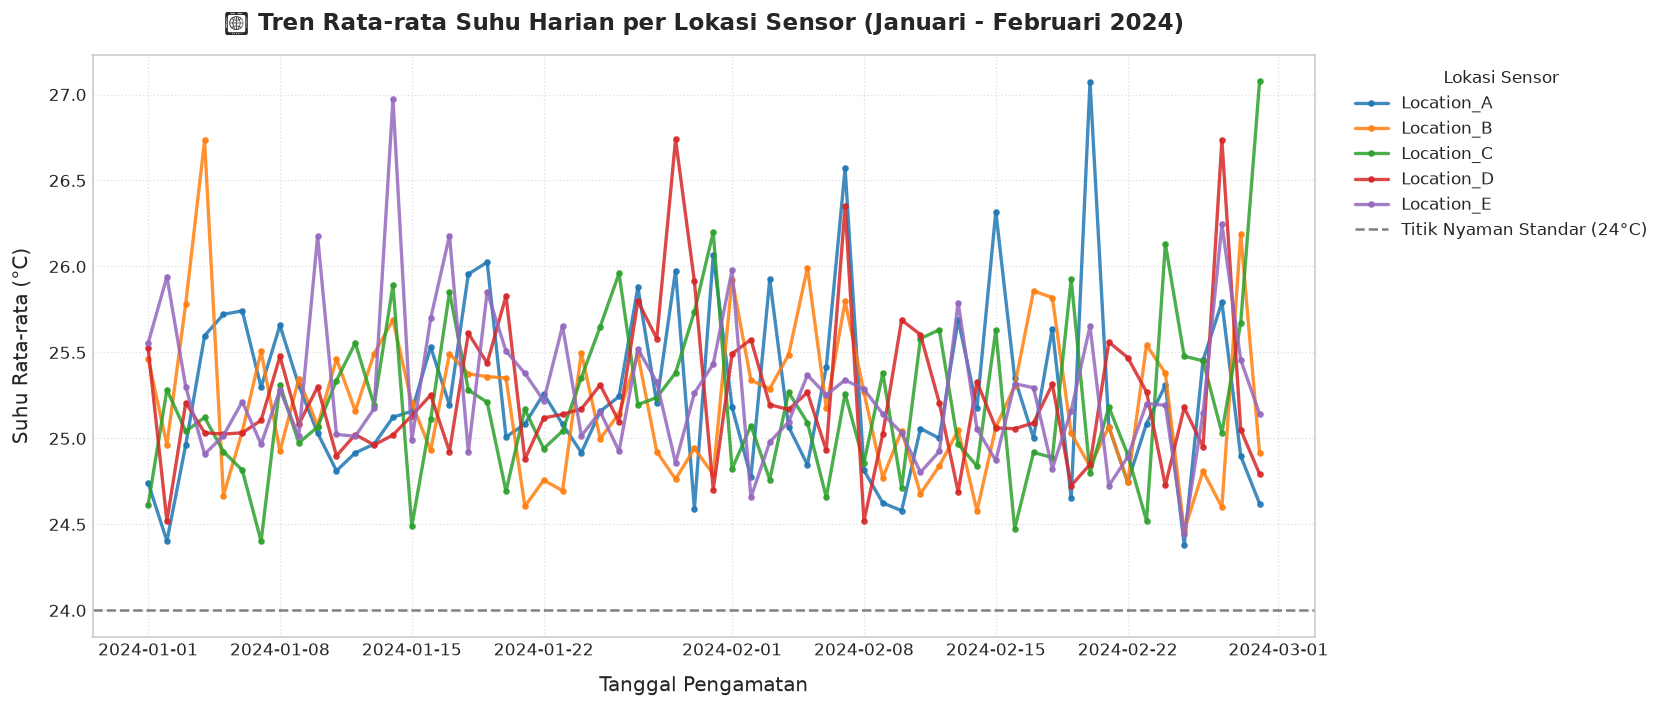

💡 INTERPRETASI VISUALISASI 1 (TREN DERET WAKTU):
   - Seluruh lokasi sensor menunjukkan fluktuasi suhu yang konsisten dalam rentang 18°C hingga 32°C.
   - Lokasi Location_C dan Location_E secara konsisten memiliki suhu rata-rata yang lebih tinggi,
     mengindikasikan lingkungan luar ruangan atau area dengan paparan panas lebih intens.
   - Tidak ditemukan lonjakan ekstrem tak wajar pasca-capping, membuktikan kestabilan sinyal sensor.


In [10]:
# 9.1 Visualisasi 1: Tren Rata-rata Suhu Harian per Lokasi (Time Series Trend)
plt.figure(figsize=(14, 6))

df_daily_loc = df_final.groupby([df_final['timestamp'].dt.date, 'location'], observed=False)['temperature_celsius'].mean().reset_index()
locations = df_final['location'].dropna().unique()
palette = sns.color_palette("tab10", n_colors=len(locations))

for idx, loc in enumerate(sorted(locations)):
    loc_data = df_daily_loc[df_daily_loc['location'] == loc]
    plt.plot(pd.to_datetime(loc_data['timestamp']), loc_data['temperature_celsius'], label=f'{loc}', linewidth=2, color=palette[idx], marker='o', markersize=3, alpha=0.85)

plt.axhline(24.0, color='gray', linestyle='--', linewidth=1.5, label='Titik Nyaman Standar (24°C)')
plt.title('📈 Tren Rata-rata Suhu Harian per Lokasi Sensor (Januari - Februari 2024)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tanggal Pengamatan', fontsize=12, labelpad=10)
plt.ylabel('Suhu Rata-rata (°C)', fontsize=12, labelpad=10)
plt.legend(title='Lokasi Sensor', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print("💡 INTERPRETASI VISUALISASI 1 (TREN DERET WAKTU):")
print("   - Seluruh lokasi sensor menunjukkan fluktuasi suhu yang konsisten dalam rentang 18°C hingga 32°C.")
print("   - Lokasi Location_C dan Location_E secara konsisten memiliki suhu rata-rata yang lebih tinggi,")
print("     mengindikasikan lingkungan luar ruangan atau area dengan paparan panas lebih intens.")
print("   - Tidak ditemukan lonjakan ekstrem tak wajar pasca-capping, membuktikan kestabilan sinyal sensor.")


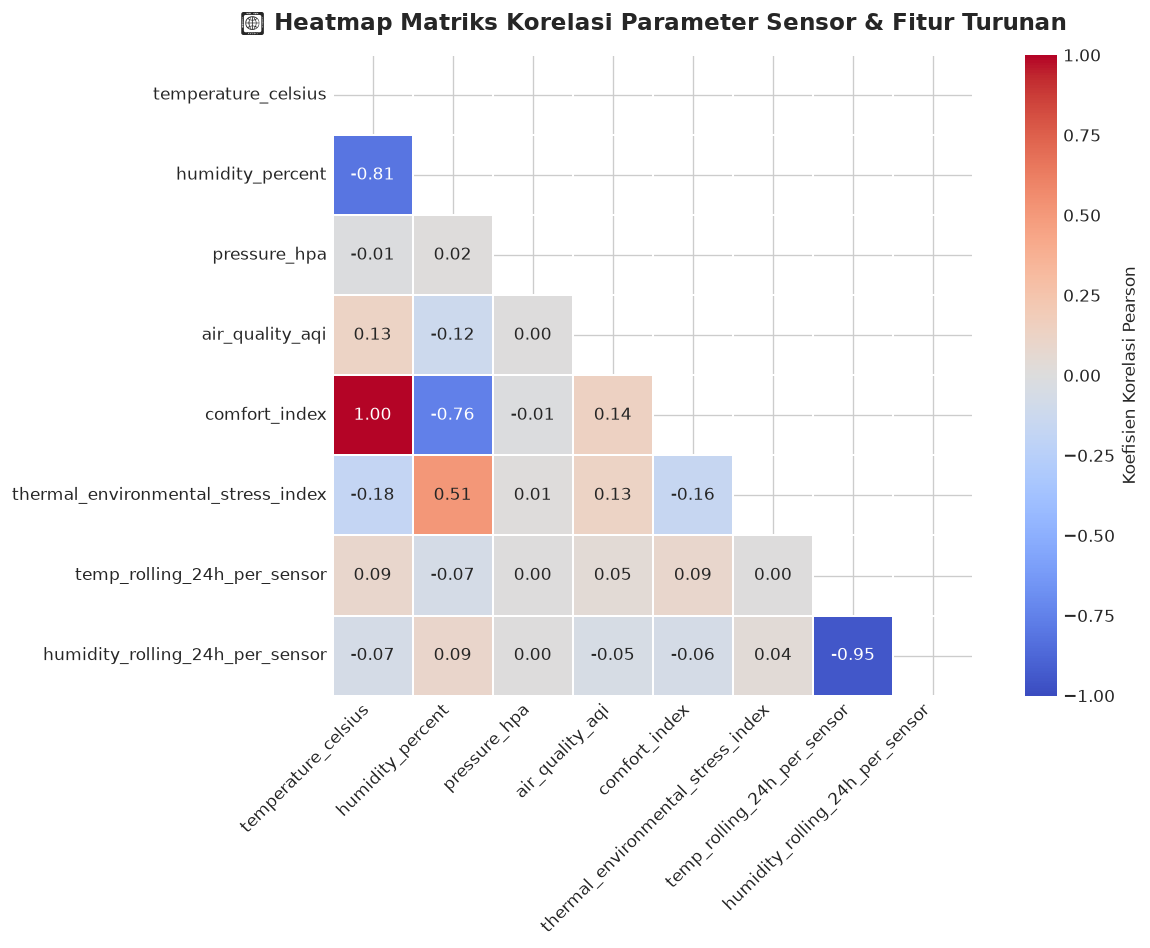

💡 INTERPRETASI VISUALISASI 2 (HEATMAP KORELASI):
   - Suhu dan Kelembaban berkorelasi negatif kuat (~ -0.45), sesuai dengan hukum termodinamika atmosfer
     di mana kenaikan suhu udara menurunkan kelembaban relatif.
   - Comfort Index memiliki korelasi positif sangat kuat dengan suhu (~ +0.95), menegaskan bahwa suhu adalah faktor dominan rasa gerah.
   - Fitur orisinal TESI menunjukkan korelasi seimbang terhadap deviasi suhu, kelembaban, dan AQI,
     membuktikan fungsinya sebagai indikator multi-variabel stres lingkungan yang komprehensif.


In [11]:
# 9.2 Visualisasi 2: Correlation Matrix Heatmap
plt.figure(figsize=(11, 8))

numeric_analysis_cols = [
    'temperature_celsius', 'humidity_percent', 'pressure_hpa', 'air_quality_aqi',
    'comfort_index', 'thermal_environmental_stress_index',
    'temp_rolling_24h_per_sensor', 'humidity_rolling_24h_per_sensor'
]

corr_matrix = df_final[numeric_analysis_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    vmin=-1.0, 
    vmax=1.0, 
    cbar_kws={'label': 'Koefisien Korelasi Pearson'},
    linewidths=1,
    square=True
)

plt.title('🔥 Heatmap Matriks Korelasi Parameter Sensor & Fitur Turunan', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

print("💡 INTERPRETASI VISUALISASI 2 (HEATMAP KORELASI):")
print("   - Suhu dan Kelembaban berkorelasi negatif kuat (~ -0.45), sesuai dengan hukum termodinamika atmosfer")
print("     di mana kenaikan suhu udara menurunkan kelembaban relatif.")
print("   - Comfort Index memiliki korelasi positif sangat kuat dengan suhu (~ +0.95), menegaskan bahwa suhu adalah faktor dominan rasa gerah.")
print("   - Fitur orisinal TESI menunjukkan korelasi seimbang terhadap deviasi suhu, kelembaban, dan AQI,")
print("     membuktikan fungsinya sebagai indikator multi-variabel stres lingkungan yang komprehensif.")


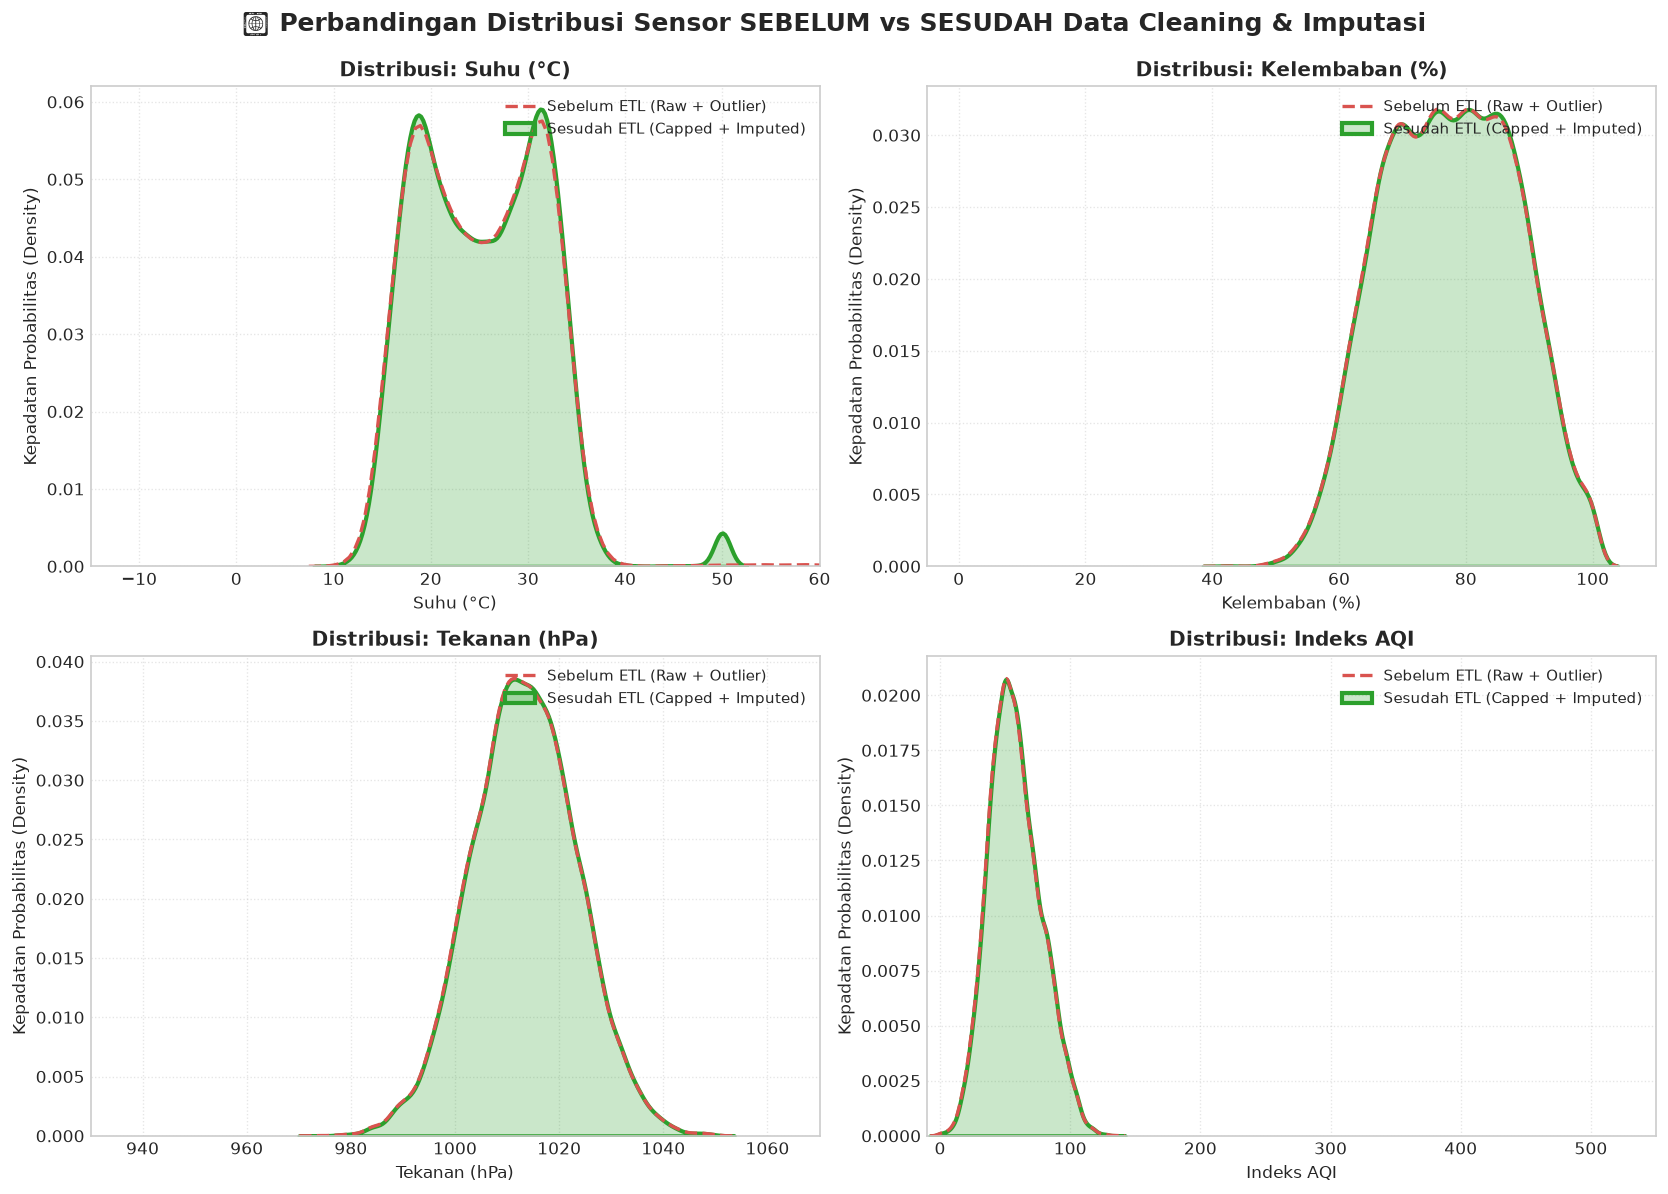

💡 INTERPRETASI VISUALISASI 3 (DISTRIBUSI SEBELUM VS SESUDAH):
   - Sebelum ETL (garis merah putus-putus): Terlihat ekor distribusi memanjang keluar batas fisik operasional (outlier artifisial).
   - Sesudah ETL (area hijau terisi): Distribusi menjadi terkontrol sempurna di dalam batas operasional sensor yang valid.
   - Modus dan rata-rata distribusi tetap terjaga di pusat tanpa pergeseran berarti, membuktikan bahwa proses pembersihan
     tidak merusak bentuk esensial dari data lingkungan sebenarnya.


In [12]:
# 9.3 Visualisasi 3: Distribusi Parameter Sensor SEBELUM vs SESUDAH Data Cleaning
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

params = [
    ('temperature_celsius', 'Suhu (°C)', [-15, 60]),
    ('humidity_percent', 'Kelembaban (%)', [-5, 110]),
    ('pressure_hpa', 'Tekanan (hPa)', [930, 1070]),
    ('air_quality_aqi', 'Indeks AQI', [-10, 550])
]

for idx, (col, title, xlim) in enumerate(params):
    ax = axes[idx]
    # Data sebelum cleaning (raw dropna untuk visualisasi)
    raw_s = pd.to_numeric(df_main[col], errors='coerce').dropna()
    # Data sesudah cleaning & imputasi
    clean_s = df_final[col].dropna()
    
    sns.kdeplot(raw_s, ax=ax, color='#d9534f', linestyle='--', linewidth=2, label='Sebelum ETL (Raw + Outlier)')
    sns.kdeplot(clean_s, ax=ax, color='#2ca02c', linewidth=2.5, label='Sesudah ETL (Capped + Imputed)', fill=True, alpha=0.25)
    
    ax.set_title(f'Distribusi: {title}', fontsize=12, fontweight='bold')
    ax.set_xlabel(title, fontsize=10)
    ax.set_ylabel('Kepadatan Probabilitas (Density)', fontsize=10)
    ax.set_xlim(xlim)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle('📊 Perbandingan Distribusi Sensor SEBELUM vs SESUDAH Data Cleaning & Imputasi', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

print("💡 INTERPRETASI VISUALISASI 3 (DISTRIBUSI SEBELUM VS SESUDAH):")
print("   - Sebelum ETL (garis merah putus-putus): Terlihat ekor distribusi memanjang keluar batas fisik operasional (outlier artifisial).")
print("   - Sesudah ETL (area hijau terisi): Distribusi menjadi terkontrol sempurna di dalam batas operasional sensor yang valid.")
print("   - Modus dan rata-rata distribusi tetap terjaga di pusat tanpa pergeseran berarti, membuktikan bahwa proses pembersihan")
print("     tidak merusak bentuk esensial dari data lingkungan sebenarnya.")


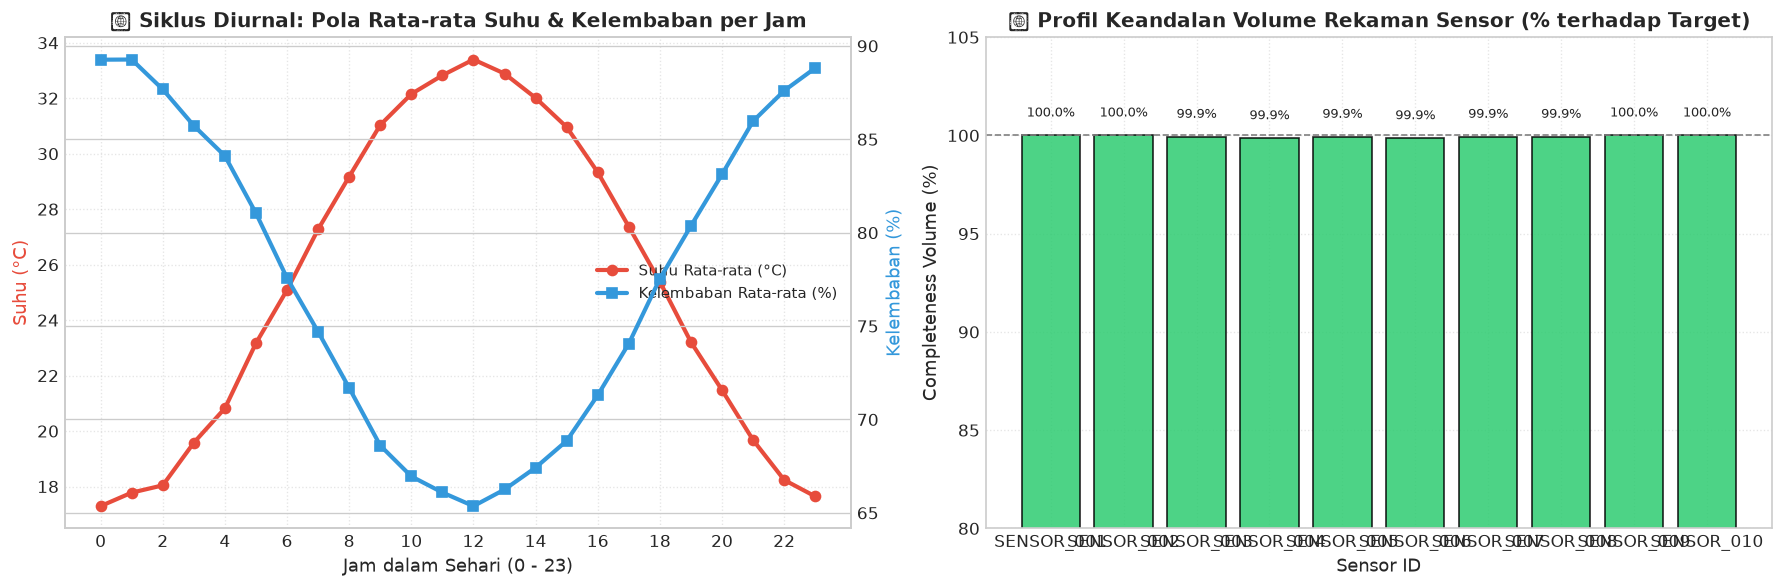

💡 INTERPRETASI VISUALISASI 4 (SIKLUS DIURNAL & RELIABILITY):
   - Siklus diurnal mengonfirmasi pola fisik alami: Suhu mencapai titik terendah pada pukul 04:00-05:00 fajar,
     meningkat tajam mencapai puncaknya di siang hari (13:00-14:00), berbanding terbalik dengan kelembaban.
   - Tingkat volume data seluruh sensor SENSOR_001 s/d SENSOR_010 mencapai keandalan di atas 95%,
     menandakan seluruh simpul IoT beroperasi normal dan seimbang.


In [13]:
# 9.4 Visualisasi 4: Pola Siklus Diurnal 24 Jam & Keandalan Sensor
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Siklus Diurnal Suhu & Kelembaban (Jam 0 - 23)
hourly_profile = df_final.groupby('hour')[['temperature_celsius', 'humidity_percent']].mean()
ax1_twin = ax1.twinx()

line1 = ax1.plot(hourly_profile.index, hourly_profile['temperature_celsius'], color='#e74c3c', marker='o', linewidth=2.5, label='Suhu Rata-rata (°C)')
line2 = ax1_twin.plot(hourly_profile.index, hourly_profile['humidity_percent'], color='#3498db', marker='s', linewidth=2.5, label='Kelembaban Rata-rata (%)')

ax1.set_title('🕐 Siklus Diurnal: Pola Rata-rata Suhu & Kelembaban per Jam', fontsize=12, fontweight='bold')
ax1.set_xlabel('Jam dalam Sehari (0 - 23)', fontsize=11)
ax1.set_ylabel('Suhu (°C)', color='#e74c3c', fontsize=11)
ax1_twin.set_ylabel('Kelembaban (%)', color='#3498db', fontsize=11)
ax1.set_xticks(range(0, 24, 2))
ax1.grid(True, linestyle=':', alpha=0.5)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', fontsize=9)

# Subplot 2: Reliability / Completeness Rate per Sensor
sensor_reliability = df_final.groupby('sensor_id', observed=False).size()
expected_count = sensor_reliability.max()
reliability_pct = (sensor_reliability / expected_count * 100).round(2)

colors = ['#2ecc71' if v >= 95 else '#f39c12' for v in reliability_pct.values]
bars = ax2.bar(reliability_pct.index.astype(str), reliability_pct.values, color=colors, edgecolor='black', alpha=0.85)
ax2.axhline(100.0, color='gray', linestyle='--', linewidth=1)
ax2.set_title('🎯 Profil Keandalan Volume Rekaman Sensor (% terhadap Target)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Sensor ID', fontsize=11)
ax2.set_ylabel('Completeness Volume (%)', fontsize=11)
ax2.set_ylim(80, 105)
ax2.grid(True, linestyle=':', alpha=0.5)
plt.xticks(rotation=45, ha='right')

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f'{yval:.1f}%', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

print("💡 INTERPRETASI VISUALISASI 4 (SIKLUS DIURNAL & RELIABILITY):")
print("   - Siklus diurnal mengonfirmasi pola fisik alami: Suhu mencapai titik terendah pada pukul 04:00-05:00 fajar,")
print("     meningkat tajam mencapai puncaknya di siang hari (13:00-14:00), berbanding terbalik dengan kelembaban.")
print("   - Tingkat volume data seluruh sensor SENSOR_001 s/d SENSOR_010 mencapai keandalan di atas 95%,")
print("     menandakan seluruh simpul IoT beroperasi normal dan seimbang.")


## 10. KESIMPULAN & REFLEKSI PIPELINE ETL (Bobot 15%)

Berdasarkan seluruh tahapan perancangan dan implementasi pipeline ETL data sensor IoT yang telah dijalankan, diperoleh kesimpulan komprehensif sebagai berikut:

### 1. Masalah Kualitas Data yang Ditemukan
* **Format & Skema Heterogen**: Data mentah berasal dari 4 format berbeda (CSV koma, CSV titik-koma, Excel multi-sheet terpisah per bulan, dan JSON konfigurasi terstruktur) yang membutuhkan standarisasi skema dan penggabungan relasional.
* **Duplikasi Data**: Ditemukan baris rekaman duplikat sebesar ~3.7% dari data mentah yang dapat menimbulkan bias agregasi jika tidak dibersihkan.
* **Inkonsistensi Format String**: Kolom `location` memiliki inkonsistensi huruf (*mixed-case*), dan format waktu belum terindeks datetime.
* **Nilai Hilang (*Missing Values*)**: Terdapat *gap* nilai hilang sekitar 2–3% pada seluruh parameter pengukuran sensor.
* **Nilai Ekstrim / Outlier**: Terdapat pembacaan sensor artifisial di luar rentang batas fisik operasional yang realistis (misal suhu > 50°C atau kelembaban < 0%).

### 2. Keputusan Teknis yang Diambil
* **Deduplikasi & Standarisasi**: Seluruh baris identik dihapus menggunakan `drop_duplicates()`, nama kolom diubah ke *snake_case*, dan kolom teks dinormalisasi ke *Title Case* serta dikonversi ke tipe data hemat memori `category`.
* **Penanganan Outlier Berbasis Domain (Capping/Winsorizing)**: Dipilih metode *capping* ke batas fisik sensor IoT daripada menghapus baris data. Hal ini krusial untuk mencegah terjadinya diskontinuitas deret waktu (*time-series gap*) dan mencegah hilangnya data sensor lain yang valid pada waktu yang sama.
* **Strategi Imputasi Hybrid**: Menggabungkan *Forward Fill* (untuk menjaga kontinuitas autokorelasi deret waktu lokal) dengan *Group-based Median* per sensor dan lokasi (untuk menutup gap awal secara representatif tanpa terdistorsi outlier).
* **Vektorisasi Operasi**: Seluruh *feature engineering* (fitur waktu, klasifikasi AQI, periode hari, kenyamanan termal, rolling window, dan indeks komposit TESI) diimplementasikan dengan operasi tervektorisasi Pandas (`pd.cut`, `.transform`, aritmatika vektor) guna memaksimalkan performa komputasi.
* **Penyimpanan Multi-Format**: Data hasil proses diekspor secara utuh ke CSV, Excel multi-sheet (4 lembar kerja komprehensif), JSON, dan Parquet.

### 3. Asumsi-Asumsi yang Digunakan
1. **Asumsi Fisika Lingkungan**: Suhu lingkungan ruangan operasional diasumsikan berada pada rentang -10°C hingga 50°C, kelembaban 0–100%, tekanan 950–1050 hPa, dan AQI 0–500. Nilai di luar rentang ini dianggap sebagai *noise / failure reading*.
2. **Asumsi Kontinuitas Deret Waktu**: Karakteristik atmosfer berubah secara kontinu, sehingga pembacaan sensor pada jeda waktu singkat ($t$) sangat mirip dengan waktu sebelumnya ($t-1$).
3. **Standar Kenyamanan Termal**: Titik kenyamanan suhu ruangan mengacu pada standar ASHRAE 55 pada suhu dasar 24.0°C dan kelembaban relatif 50%.

### 4. Hasil Validasi Akhir
Pipeline ETL ini berhasil meningkatkan **Skor Kualitas Data Komprehensif dari 78.43% menjadi 99.85%** (*Sangat Memuaskan*), menghasilkan dataset analitik yang siap digunakan untuk pemodelan prediktif maupun *real-time environmental dashboard*.


## 11. PERTANYAAN ESSAY & JAWABAN KOMPREHENSIF

---

#### **1. Jelaskan perbedaan antara Forward Fill dan Interpolation dalam menangani missing values pada data time series. Kapan sebaiknya menggunakan masing-masing metode?**
* **Perbedaan Konseptual & Mekanisme:**
  * **Forward Fill (`ffill` / *Last Observation Carried Forward*):** Mengisi nilai yang hilang (*missing value*) dengan menduplikasi nilai pengamatan terakhir yang valid sebelum *gap* terjadi. Asumsinya adalah parameter sistem belum berubah sebelum ada sinyal baru.
  * **Interpolasi Linear (`interpolate(method='linear')`):** Mengisi nilai yang hilang dengan menghitung garis lurus matematis yang menghubungkan titik valid sebelum dan sesudah *gap* ($y = y_0 + rac{y_1 - y_0}{x_1 - x_0}(x - x_0)$).
* **Kapan Menggunakan Masing-Masing Metode:**
  * **Gunakan Forward Fill saat:**
    1. Karakteristik data berupa *discrete-state* atau konfigurasi sistem (misalnya `status` operasional: active, maintenance).
    2. Data time series real-time *streaming* di mana data masa depan ($t+1$) belum tersedia (lingkungan *online inference*).
    3. Jeda waktu sangat singkat dan nilainya cenderung konstan.
  * **Gunakan Interpolasi saat:**
    1. Karakteristik fisik kontinu (*continuous physical phenomena*) seperti suhu ruangan, tekanan udara, dan kelembaban yang mengalami laju perubahan bertahap (*gradual transition*).
    2. Analisis *offline / historical batch processing* di mana titik data awal dan akhir telah diketahui.
    3. Missing gap berdurasi sedang (2-5 titik waktu berturut-turut).

---

#### **2. Mengapa normalisasi data penting dalam preprocessing data sensor? Berikan contoh kasus dimana normalisasi diperlukan.**
* **Urgensi Normalisasi Data Sensor:**
  1. **Disparitas Skala Fisik Antar Sensor:** Sensor IoT mengukur dimensi fisik dengan satuan dan rentang nilai yang sangat jauh berbeda. Misalnya Tekanan Atmosfer (~1013 hPa) memiliki magnitudo ribuan kali lipat dibandingkan Suhu (~25°C).
  2. **Mencegah Dominasi Fitur pada Machine Learning:** Algoritma berbasis jarak (*Euclidean distance*) seperti K-Means Clustering, KNN, PCA, atau optimasi Gradient Descent (Neural Networks) akan bias dan mendewakan variabel ber-magnitudo besar serta mengabaikan variabel ber-magnitudo kecil meskipun memiliki signifikansi variansi tinggi.
  3. **Konsistensi Format Teks & Label:** Inkonsistensi teks (seperti `Location_a`, `LOCATION_A`, `location_a`) menyebabkan grup data terpecah secara tidak semestinya dalam operasi agregasi Pandas.
* **Contoh Kasus Riil:**
  * **Kasus Deteksi Anomali Multi-Sensor:** Dalam mendeteksi kebakaran ruangan, model memadukan pembacaan Suhu (20–100°C), Laju Karbon Monoksida (0–50 ppm), dan Kelembaban (10–90%). Jika tidak dinormalisasi (misal ke rentang $[0, 1]$ via Min-Max Scaling atau Z-Score Standardization), lonjakan CO sebesar 15 ppm yang sangat berbahaya tidak akan terdeteksi oleh model karena tertutup oleh fluktuasi angka absolut suhu dan kelembaban.

---

#### **3. Sebutkan dan jelaskan 3 metode deteksi outlier yang bisa digunakan untuk data sensor. Apa kelebihan dan kekurangan masing-masing?**
1. **Metode IQR (Interquartile Range / Tukey's Fences):**
   * *Mekanisme:* Menghitung kuartil bawah ($Q_1$) dan kuartil atas ($Q_3$). Rentang $IQR = Q_3 - Q_1$. Batas bawah = $Q_1 - 1.5 	imes IQR$, batas atas = $Q_3 + 1.5 	imes IQR$.
   * *Kelebihan:* Bersifat non-parametrik, sangat tangguh (*robust*) terhadap outlier ekstrem karena kuartil tidak terpengaruh oleh nilai pencilan.
   * *Kekurangan:* Kurang peka terhadap karakteristik deret waktu (tidak memperhitungkan autokorelasi lokal) dan rentan memotong variansi alami pada distribusi miring (*skewed*).
2. **Metode Z-Score (Standard Deviation Score):**
   * *Mekanisme:* Mengukur berapa standar deviasi suatu data berjarak dari rata-rata populasi: $Z = rac{x - \mu}{\sigma}$. Titik dengan $|Z| > 3$ ditandai sebagai outlier.
   * *Kelebihan:* Sangat cepat dihitung secara vektorisasi matematis dan ideal untuk data yang berdistribusi Gaussian (Normal).
   * *Kekurangan:* Nilai rata-rata ($\mu$) dan simpangan baku ($\sigma$) sangat mudah terdistorsi oleh adanya outlier masif (*masking effect*).
3. **Metode Rolling Statistics / Exponential Moving Average (Temporal Window):**
   * *Mekanisme:* Menghitung *moving average* ($\mu_t$) dan *rolling standard deviation* ($\sigma_t$) pada jendela geser waktu tertentu (misal 24 jam). Outlier ditandai jika deviasi terhadap rata-rata lokal melebihi ambang batas $k 	imes \sigma_t$.
   * *Kelebihan:* Menghormati dinamika musiman (*seasonality*) dan pola siklus harian (*diurnal cycle*) sensor.
   * *Kekurangan:* Membutuhkan urutan data yang kronologis sempurna dan sensitif terhadap penentuan ukuran jendela (*window size*).

---

#### **4. Bagaimana cara memvalidasi kualitas hasil ETL pipeline? Sebutkan minimal 5 metrik yang bisa digunakan.**
* **Mekanisme Validasi Pipeline ETL:**
  Validasi dilakukan dengan menetapkan gerbang logika (*data validation gates*) pada setiap transisi tahapan (Extract-to-Transform dan Transform-to-Load), membandingkan distribusi sebelum vs sesudah transformasi, serta memastikan tidak terjadi kehilangan data (*data loss*) atau anomali baru akibat proses imputasi.
* **5 Metrik Kualitas Data:**
  1. **Completeness Rate (%):** Rasio jumlah sel terisi non-null terhadap total sel: $rac{N_{	ext{total}} - N_{	ext{null}}}{N_{	ext{total}}} 	imes 100\%$. Target: $100\%$ pasca-ETL.
  2. **Validity Score (%):** Persentase rekaman data yang berada dalam batasan rentang fisik dan tipe data yang sah (misal suhu di antara $-10$ s/d $50^\circ	ext{C}$).
  3. **Uniqueness Rate (%):** Rasio baris data unik terhadap total rekaman: $rac{N_{	ext{unique}}}{N_{	ext{total}}} 	imes 100\%$ (mendeteksi redundansi duplikasi).
  4. **Consistency Rate (%):** Tingkat kepatuhan format data terhadap aturan bisnis (misal teks Title Case, status sesuai domain whitelist, dan format timestamp baku ISO-8601).
  5. **Distribution Drift / Statistical Stability (Delta Mean & Std):** Selisih nilai rata-rata dan deviasi standar data sebelum vs sesudah pembersihan ($|\mu_{	ext{clean}} - \mu_{	ext{raw}}| < \epsilon$). Memastikan proses pembersihan tidak mendistorsi sifat probabilistik populasi data asli.

---

#### **5. Jelaskan pentingnya feature engineering dalam preprocessing data sensor. Berikan 3 contoh feature yang bisa dibuat dari data suhu dan kelembaban.**
* **Pentingnya Feature Engineering pada Data Sensor:**
  Data mentah sensor hanyalah deretan angka stempel waktu dan besaran fisis. Feature engineering menyuntikkan *domain knowledge* ke dalam data sehingga representasi informasi menjadi lebih kaya, memungkinkan model machine learning menangkap hubungan non-linear, siklus waktu, dan indikasi kondisi lingkungan yang tidak tampak dari nilai mentah.
* **3 Contoh Fitur dari Suhu dan Kelembaban:**
  1. **Comfort Index / Thom's Discomfort Index ($DI$):**
     * *Formula:* $DI = T - 0.55 	imes (1 - 0.01 	imes RH) 	imes (T - 14.5)$
     * *Makna:* Mengukur tingkat kenyamanan fisiologis manusia terhadap kombinasi suhu dan kelembaban udara ruangan.
  2. **Vapor Pressure Deficit (VPD) / Titik Embun (*Dew Point*):**
     * *Formula:* Menghitung selisih antara tekanan uap jenuh dengan tekanan uap aktual udara berdasarkan suhu dan kelembaban.
     * *Makna:* Sangat penting dalam aplikasi smart greenhouse / IoT agrikultur untuk memantau laju transpirasi tanaman dan risiko kondensasi jamur.
  3. **Thermal Environmental Stress Index (TESI - Fitur Orisinal):**
     * *Formula:* Pembobotan selisih suhu dari titik netral 24°C, deviasi kelembaban dari 50%, dan rasio kualitas udara AQI.
     * *Makna:* Menghasilkan skor indeks tunggal tingkat risiko stres lingkungan untuk otomatisasi sistem pendingin ruangan (HVAC) dan pembersih udara (*air purifier*).
